Invasive_Tumor: 34398 image(s) found
DCIS_1: 12925 image(s) found
DCIS_2: 11719 image(s) found
Prolif_Invasive_Tumor: 3775 image(s) found
CD4+_T_Cells: 8453 image(s) found
CD8+_T_Cells: 6941 image(s) found
B_Cells: 4987 image(s) found
Stromal: 41424 image(s) found
Epoch 1/20


C:\Users\marka\anaconda3\envs\tfenv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 368s 3s/step - accuracy: 0.2929 - loss: 1.9380 - val_accuracy: 0.4890 - val_loss: 1.2154
Epoch 2/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 334s 3s/step - accuracy: 0.5020 - loss: 1.1804 - val_accuracy: 0.5357 - val_loss: 1.0942
Epoch 3/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 332s 3s/step - accuracy: 0.5486 - loss: 1.0789 - val_accuracy: 0.5667 - val_loss: 1.0256
Epoch 4/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 335s 3s/step - accuracy: 0.5763 - loss: 1.0215 - val_accuracy: 0.5870 - val_loss: 0.9881
Epoch 5/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 340s 3s/step - accuracy: 0.6069 - loss: 0.9666 - val_accuracy: 0.6130 - val_loss: 0.9319
Epoch 6/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 341s 3s/step - accuracy: 0.6409 - loss: 0.9000 - val_accuracy: 0.6258 - val_loss: 0.9220
Epoch 7/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 371s 3s/step - accuracy: 0.6762 - loss: 0.8272 - val_accuracy: 0.6199 - val_loss: 0.9260
Epoch 8/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 338s 3s/step - accuracy: 0.6961 - loss: 0.7931 - val_accuracy: 0.664

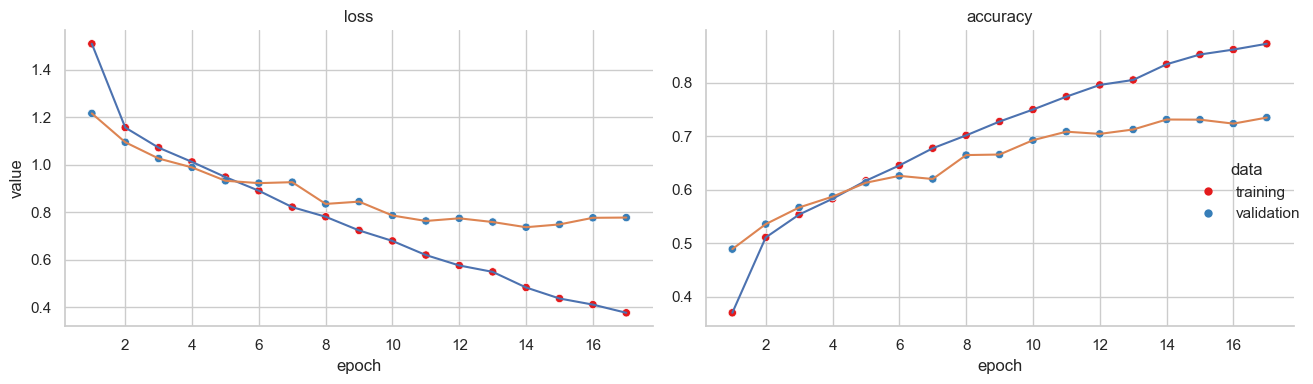

30/30 ━━━━━━━━━━━━━━━━━━━━ 23s 763ms/step
                       precision    recall  f1-score   support

         Immune_Cells       0.88      0.84      0.86      2995
       Invasive_Tumor       0.61      0.44      0.51      2995
               DCIS_1       0.79      0.84      0.81      2995
               DCIS_2       0.66      0.69      0.67      2995
Prolif_Invasive_Tumor       0.69      0.86      0.77      2995

             accuracy                           0.73     14975
            macro avg       0.73      0.73      0.72     14975
         weighted avg       0.73      0.73      0.72     14975



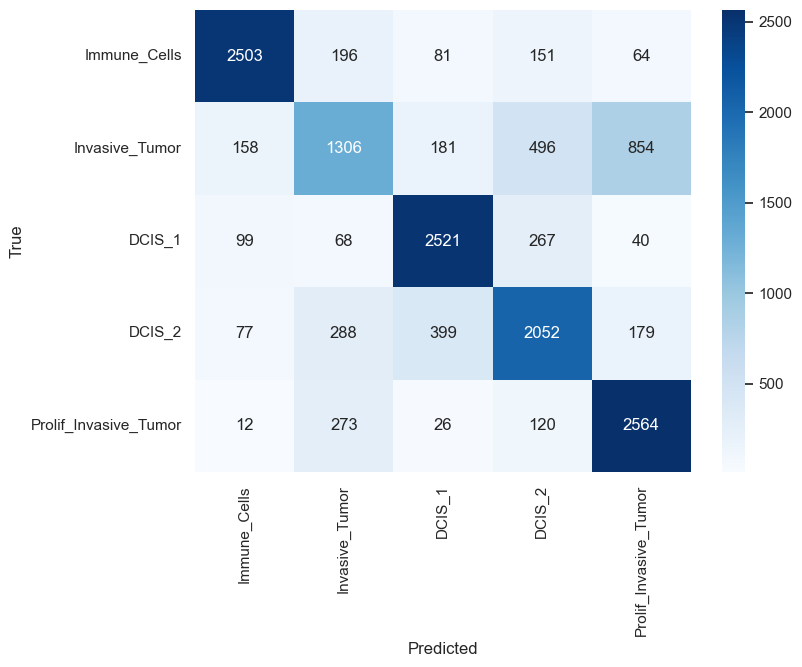

Evaluating on final holdout set of 200 images:
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 699ms/step - accuracy: 0.7197 - loss: 0.6133
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 326ms/step


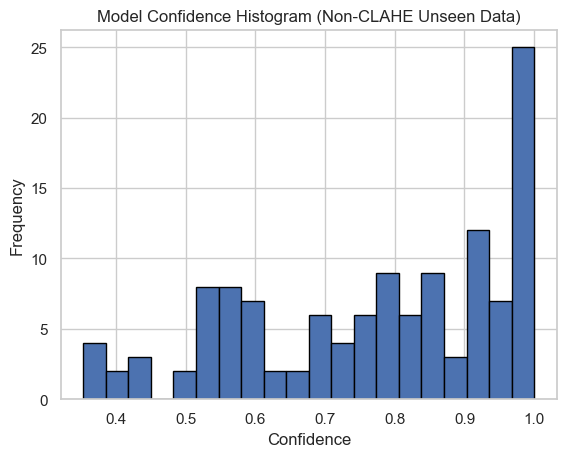

In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping

seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

img_width, img_height = 100, 100
batch_size = 512
AUTOTUNE = tf.data.AUTOTUNE

tumor_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]
immune_folders = ["CD4+_T_Cells", "CD8+_T_Cells", "B_Cells", "Stromal"]

for folder in tumor_folders + immune_folders:
    files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
    print(f"{folder}: {len(files)} image(s) found")

def get_file_label_pairs(folders, main_label):
    pairs = []
    for folder in folders:
        files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
        for f in files:
            sub_label = os.path.basename(folder)
            pairs.append((f, main_label, sub_label))
    return pairs

tumor_files = get_file_label_pairs(tumor_folders, main_label=1)
immune_files = get_file_label_pairs(immune_folders, main_label=0)
all_file_label_pairs = tumor_files + immune_files

def create_balanced_equal_dataset(file_label_pairs, target_size=15000):
    from collections import defaultdict
    label_to_files = defaultdict(list)
    for f, main_label, sub_label in file_label_pairs:
        label_to_files[sub_label].append((f, main_label, sub_label))

    balanced = []
    for sub_label, files in label_to_files.items():
        originals = files.copy()
        current_size = len(originals)

        if current_size < target_size:
            extra_needed = target_size - current_size
            oversampled = random.choices(originals, k=extra_needed)
            balanced.extend((f, m, s, False) for f, m, s in originals)
            balanced.extend((f, m, s, True) for f, m, s in oversampled)
        elif current_size > target_size:
            undersampled = random.sample(originals, k=target_size)
            balanced.extend((f, m, s, False) for f, m, s in undersampled)
        else:
            balanced.extend((f, m, s, False) for f, m, s in originals)

    random.shuffle(balanced)
    return balanced

balanced_pairs = create_balanced_equal_dataset(all_file_label_pairs, target_size=15000)

# Makes labels equal to 5 different types
def extract_labels_from_balanced_pairs(pairs):
    file_paths = []
    labels = []
    tumor_map = {
        "Invasive_Tumor": 1,
        "DCIS_1": 2,
        "DCIS_2": 3,
        "Prolif_Invasive_Tumor": 4
    }
    for f, main_label, sub_label, _ in pairs:
        label = 0 if sub_label not in tumor_map else tumor_map[sub_label]
        file_paths.append(f)
        labels.append(label)
    return np.array(file_paths), np.array(labels)

file_paths, labels = extract_labels_from_balanced_pairs(balanced_pairs)

# Does the undersampling
prolif_count = np.sum(labels == 4)
balanced_indices = []
for label in np.unique(labels):
    label_indices = np.where(labels == label)[0]
    if len(label_indices) > prolif_count:
        selected = np.random.choice(label_indices, prolif_count, replace=False)
    else:
        selected = label_indices
    balanced_indices.extend(selected)

file_paths = file_paths[balanced_indices]
labels = labels[balanced_indices]

# Shuffle
shuffle_idx = np.random.permutation(len(file_paths))
file_paths = file_paths[shuffle_idx]
labels = labels[shuffle_idx]

import collections

label_to_indices = collections.defaultdict(list)
for idx, label in enumerate(labels):
    label_to_indices[label].append(idx)

holdout_indices = []
for label in sorted(label_to_indices.keys()): 
    indices = label_to_indices[label]
    selected = np.random.choice(indices, 25, replace=False)
    holdout_indices.extend(selected)

mask = np.ones(len(labels), dtype=bool)
mask[holdout_indices] = False

final_test_files = file_paths[holdout_indices]
final_test_labels = labels[holdout_indices]

file_paths = file_paths[mask]
labels = labels[mask]

shuffle_idx = np.random.permutation(len(file_paths))
file_paths = file_paths[shuffle_idx]
labels = labels[shuffle_idx]

train_files, test_files, train_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=seed)

# Sam methods again

def decode_img(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [img_width, img_height])
    img = img / 255.0
    return img

def process_path(file_path, label):
    img = decode_img(file_path)
    return img, label

def prepare_dataset(files, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = prepare_dataset(train_files, train_labels, shuffle=True)
test_ds = prepare_dataset(test_files, test_labels)

# Now with early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',   
    patience=3,           
    restore_best_weights=True  
)

# Defines my model
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_width, img_height, 3)),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, epochs=20, validation_data=test_ds, callbacks=[early_stopping])

# All for creation of the accuracy-loss plot
hist_df = pd.DataFrame(history.history)
hist_df['epoch'] = hist_df.index + 1

hist_long = pd.melt(
    hist_df,
    id_vars='epoch',
    value_vars=['loss', 'val_loss', 'accuracy', 'val_accuracy'],
    var_name='metric',
    value_name='value'
)

hist_long['data'] = hist_long['metric'].apply(lambda x: 'training' if 'val' not in x else 'validation')
hist_long['type'] = hist_long['metric'].apply(lambda x: 'loss' if 'loss' in x else 'accuracy')

sns.set(style="whitegrid")

g = sns.relplot(
    data=hist_long,
    x="epoch", y="value",
    col="type", hue="data",
    kind="scatter", facet_kws={'sharey': False},
    palette="Set1", height=4, aspect=1.5
)

for ax, metric in zip(g.axes.flat, ['loss', 'accuracy']):
    sns.lineplot(
        data=hist_long[hist_long['type'] == metric],
        x="epoch", y="value", hue="data",
        ax=ax, legend=False
    )

g.set_titles("{col_name}")
g.set_axis_labels("epoch", "value")
plt.tight_layout()
plt.show()

# Evaluation
y_pred = model.predict(test_ds)
c = np.max(y_pred, axis=1) 
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)

target_names = ["Immune_Cells", "Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]
print(classification_report(y_true, y_pred_classes, target_names=target_names))

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Hold Out Process
def prepare_small_dataset(files, labels):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    ds = ds.map(process_path, num_parallel_calls=1)
    ds = ds.batch(64).prefetch(1)
    return ds

final_test_ds = prepare_small_dataset(final_test_files, final_test_labels)

print("Evaluating on final holdout set of 200 images:")
model.evaluate(final_test_ds)

y_final_pred = model.predict(final_test_ds)
c = np.max(y_final_pred, axis=1) 

plt.hist(c, bins=20, edgecolor='black')
plt.title('Model Confidence Histogram (Non-CLAHE Unseen Data)')
plt.xlabel('Confidence')
plt.ylabel('Frequency')
plt.show()

np.save("confidence_values_1.npy", c)
np.save("y_pred_1.npy", y_final_pred)
np.save("y_true_1.npy", final_test_labels)
hist_df.to_csv("training_history_1.csv", index=False)



In [2]:
np.save("valset_y_pred.npy", y_pred)
np.save("valset_y_true.npy", y_true)

30/30 ━━━━━━━━━━━━━━━━━━━━ 23s 762ms/step


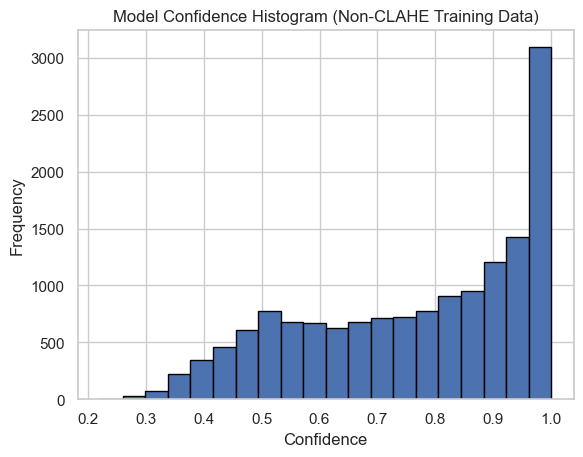

In [3]:
y_pred = model.predict(test_ds)
c = np.max(y_pred, axis=1) 

plt.hist(c, bins=20, edgecolor='black')
plt.title('Model Confidence Histogram (Non-CLAHE Training Data)')
plt.xlabel('Confidence')
plt.ylabel('Frequency')
plt.show()

np.save("confidence_values_training.npy", c)

model.save("multiclass_MS_NONCLAHE.keras")